# Mô Hình Mạng Tích Chập (CNN) Thuần NumPy Trên Toàn Bộ Dữ Liệu CIFAR-10

Khác với ảnh xám đơn sắc căn giữa như MNIST, **CIFAR-10 là tập dữ liệu ảnh màu tự nhiên (RGB 3 kênh)** kích thước $32 \times 32$ với 10 lớp vật thể đa dạng (`airplane`, `automobile`, `bird`, `cat`, `deer`, `dog`, `frog`, `horse`, `ship`, `truck`) trong bối cảnh thực tế phức tạp.

Notebook này triển khai mạng CNN hoàn chỉnh từ đầu (Pure NumPy) với cấu trúc module hóa cao và tuân thủ các nguyên lý khoa học:
1. **Dữ liệu đầy đủ (Full Dataset):** Phân chia toàn bộ 60,000 mẫu thành **Train (40,000 mẫu - 4,000 mẫu/lớp)**, **Validation (10,000 mẫu - 1,000 mẫu/lớp)** và **Test (10,000 mẫu - 1,000 mẫu/lớp)** theo phương pháp phân tầng (Stratified Split).
2. **Thuật toán tối ưu cơ bản:** Sử dụng thuần túy **Mini-batch Gradient Descent (`MiniBatchGD`)** theo đúng yêu cầu lý thuyết (không dùng Momentum hay Adam).
3. **Đối sánh thực nghiệm giữa 2 kiến trúc:**
   * **Baseline Scratch CNN:** 1 tầng tích chập 8 filters $3 \times 3$, không viền đệm (`padding=0`), khởi tạo Standard Normal $\mathcal{N}(0, 0.05)$, tầng Dense 64 units.
   * **Improved Scratch CNN:** Khởi tạo trọng số **He Normal** (Kaiming Init), bổ sung viền đệm **Zero-Padding (`padding=1`)** bảo tồn kích thước biên, mở rộng dung lượng biểu diễn với 16 filters $3 \times 3$ và tầng Dense 128 units.
4. **Theo dõi quá trình huấn luyện:** Ghi nhận cả Train Loss, Train Acc, Val Loss, Val Acc ở từng epoch và vẽ biểu đồ đường cong đối sánh (**Train vs. Val Curves**).
5. **Đánh giá kiểm thử độc lập:** Tách riêng ô đánh giá trên tập **Test** với đầy đủ các chỉ số (Accuracy, Precision, Recall, Macro F1, Weighted F1) và vẽ **Ma trận nhầm lẫn (Confusion Matrix)**.


In [1]:
import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report
from sklearn.model_selection import train_test_split

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.sans-serif'] = 'Arial'
plt.rcParams['font.size'] = 11

FIGURES_DIR = '../reports/figures'
if not os.path.exists(FIGURES_DIR):
    for p in ['cifar10/reports/figures', 'src/Assigment 04/cifar10/reports/figures']:
        if os.path.exists(p) or os.path.exists(os.path.dirname(p)):
            FIGURES_DIR = p
            break
os.makedirs(FIGURES_DIR, exist_ok=True)

REPORTS_DIR = '../reports'
if not os.path.exists(REPORTS_DIR):
    for p in ['cifar10/reports', 'src/Assigment 04/cifar10/reports']:
        if os.path.exists(p) or os.path.exists(os.path.dirname(p)):
            REPORTS_DIR = p
            break
os.makedirs(REPORTS_DIR, exist_ok=True)


In [2]:
DATA_PATH = '../data/cifar10.npz'
if not os.path.exists(DATA_PATH):
    for p in ['cifar10/data/cifar10.npz', 'src/Assigment 04/cifar10/data/cifar10.npz', 'data/cifar10.npz']:
        if os.path.exists(p):
            DATA_PATH = p
            break

data = np.load(DATA_PATH)
X_train_raw = data['X_train']  # (50000, 32, 32, 3)
y_train_raw = data['y_train'].astype(np.int64)
X_test_raw = data['X_test']    # (10000, 32, 32, 3)
y_test = data['y_test'].astype(np.int64)

CLASS_NAMES = ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
CLASS_NAMES_VN = ['Máy bay', 'Ô tô', 'Chim', 'Mèo', 'Hươu', 'Chó', 'Ếch', 'Ngựa', 'Tàu thủy', 'Xe tải']

# Phân chia phân tầng (Stratified Split): 50,000 ban đầu -> 40,000 Train (80%) và 10,000 Val (20%)
X_train_split, X_val_split, y_train, y_val = train_test_split(
    X_train_raw, y_train_raw, test_size=0.2, stratify=y_train_raw, random_state=RANDOM_SEED
)

# Chuyển đổi định dạng sang Channel-First (N, C, H, W) = (N, 3, 32, 32) và chuẩn hóa về đoạn [0, 1]
X_train = (X_train_split.transpose(0, 3, 1, 2) / 255.0).astype(np.float32)
X_val = (X_val_split.transpose(0, 3, 1, 2) / 255.0).astype(np.float32)
X_test = (X_test_raw.transpose(0, 3, 1, 2) / 255.0).astype(np.float32)

print("=== KÍCH THƯỚC VÀ PHÂN PHỐI TẬP DỮ LIỆU CIFAR-10 ===")
print(f"Tập Train:      X = {X_train.shape}, y = {y_train.shape} -> Phân phối: {np.bincount(y_train)}")
print(f"Tập Validation: X = {X_val.shape},   y = {y_val.shape}   -> Phân phối: {np.bincount(y_val)}")
print(f"Tập Test:       X = {X_test.shape},  y = {y_test.shape}  -> Phân phối: {np.bincount(y_test)}")


=== KÍCH THƯỚC VÀ PHÂN PHỐI TẬP DỮ LIỆU CIFAR-10 ===
Tập Train:      X = (40000, 3, 32, 32), y = (40000,) -> Phân phối: [4000 4000 4000 4000 4000 4000 4000 4000 4000 4000]
Tập Validation: X = (10000, 3, 32, 32),   y = (10000,)   -> Phân phối: [1000 1000 1000 1000 1000 1000 1000 1000 1000 1000]
Tập Test:       X = (10000, 3, 32, 32),  y = (10000,)  -> Phân phối: [1000 1000 1000 1000 1000 1000 1000 1000 1000 1000]


In [3]:
# ==============================================================================
# CÁC HÀM TIỆN ÍCH VECTOR HÓA PHÉP TÍCH CHẬP ĐA KÊNH (IM2COL / COL2IM)
# ==============================================================================

def get_im2col_indices(x_shape, field_height=3, field_width=3, padding=0, stride=1):
    '''
    Tính ma trận chỉ số không gian (spatial indices) phục vụ trích xuất cửa sổ trượt tích chập.
    
    Tham số:
        x_shape (tuple): Kích thước tensor đầu vào dạng (N, C, H, W).
        field_height (int): Chiều cao của bộ lọc tích chập (kernel height).
        field_width (int): Chiều rộng của bộ lọc tích chập (kernel width).
        padding (int): Độ dày viền đệm zero-padding xung quanh ảnh.
        stride (int): Bước trượt của bộ lọc.
        
    Trả về:
        tuple (k, i, j): Bộ 3 mảng chỉ số tương ứng kênh màu, tọa độ hàng và tọa độ cột.
    '''
    N, C, H, W = x_shape
    out_height = int((H + 2 * padding - field_height) / stride + 1)
    out_width = int((W + 2 * padding - field_width) / stride + 1)
    i0 = np.repeat(np.arange(field_height), field_width)
    i0 = np.tile(i0, C)
    i1 = stride * np.repeat(np.arange(out_height), out_width)
    j0 = np.tile(np.arange(field_width), field_height * C)
    j1 = stride * np.tile(np.arange(out_width), out_height)
    i = i0.reshape(-1, 1) + i1.reshape(1, -1)
    j = j0.reshape(-1, 1) + j1.reshape(1, -1)
    k = np.repeat(np.arange(C), field_height * field_width).reshape(-1, 1)
    return (k.astype(int), i.astype(int), j.astype(int))




In [ ]:
def im2col_indices(x, field_height=3, field_width=3, padding=0, stride=1):
    '''
    Chuyển đổi tensor 4D đa kênh (N, C, H, W) thành ma trận cột 2D (C*Kh*Kw, N*Hout*Wout)
    giúp quy đổi phép tích chập đa kênh thành phép nhân ma trận (GEMM) tốc độ cao.
    
    Tham số:
        x (ndarray): Tensor ảnh đầu vào có kích thước (N, C, H, W).
        field_height (int): Chiều cao của bộ lọc kernel.
        field_width (int): Chiều rộng của bộ lọc kernel.
        padding (int): Độ dày viền đệm zero-padding.
        stride (int): Bước trượt.
        
    Trả về:
        cols (ndarray): Ma trận 2D kích thước (C * field_height * field_width, N * out_height * out_width).
    '''
    p = padding
    if p > 0:
        x_padded = np.pad(x, ((0, 0), (0, 0), (p, p), (p, p)), mode='constant')
    else:
        x_padded = x
    k, i, j = get_im2col_indices(x.shape, field_height, field_width, padding, stride)
    cols = x_padded[:, k, i, j]
    C = x.shape[1]
    cols = cols.transpose(1, 2, 0).reshape(field_height * field_width * C, -1)
    return cols



In [ ]:
def col2im_indices(cols, x_shape, field_height=3, field_width=3, padding=0, stride=1):
    '''
    Tái tạo lại tensor gradient 4D (N, C, H, W) từ ma trận gradient dạng cột 2D (col2im)
    trong quá trình lan truyền ngược (backward pass).
    
    Tham số:
        cols (ndarray): Ma trận gradient dX_cols kích thước (C * Kh * Kw, N * Hout * Wout).
        x_shape (tuple): Kích thước tensor gốc ban đầu (N, C, H, W).
        field_height (int): Chiều cao của bộ lọc tích chập.
        field_width (int): Chiều rộng của bộ lọc tích chập.
        padding (int): Độ dày viền đệm zero-padding ban đầu.
        stride (int): Bước trượt tích chập.
        
    Trả về:
        x_grad (ndarray): Tensor gradient không gian kích thước (N, C, H, W).
    '''
    N, C, H, W = x_shape
    H_padded, W_padded = H + 2 * padding, W + 2 * padding
    x_padded = np.zeros((N, C, H_padded, W_padded), dtype=cols.dtype)
    k, i, j = get_im2col_indices(x_shape, field_height, field_width, padding, stride)
    cols_reshaped = cols.reshape(C * field_height * field_width, -1, N).transpose(2, 0, 1)
    np.add.at(x_padded, (slice(None), k, i, j), cols_reshaped)
    if padding == 0:
        return x_padded
    return x_padded[:, :, padding:-padding, padding:-padding]

In [ ]:
# ==============================================================================
# ĐỊNH NGHĨA CÁC LỚP MẠNG NƠ-RON TÍCH CHẬP (LAYER CLASSES)
# ==============================================================================

class Conv2D:
    '''
    Lớp tích chập 2D đa kênh RGB: thực hiện phép trượt bộ lọc không gian 3D,
    hỗ trợ khởi tạo He Normal hoặc Standard Normal, tính forward và backward bằng im2col/col2im.
    '''
    def __init__(self, in_channels, out_channels, kernel_size=3, stride=1, padding=0, init_method='he'):
        self.in_channels = in_channels
        self.out_channels = out_channels
        self.kernel_size = kernel_size
        self.stride = stride
        self.padding = padding
        fan_in = in_channels * kernel_size * kernel_size
        if init_method == 'he':
            self.W = np.random.randn(out_channels, in_channels, kernel_size, kernel_size).astype(np.float32) * np.sqrt(2.0 / fan_in)
        else:
            self.W = np.random.randn(out_channels, in_channels, kernel_size, kernel_size).astype(np.float32) * 0.05
        self.b = np.zeros((out_channels, 1), dtype=np.float32)
        self.x = None
        self.x_cols = None
        self.dW = None
        self.db = None

    def forward(self, x):
        '''Tính lan truyền xuôi: Nhân ma trận trọng số bộ lọc với ma trận cột im2col.'''
        self.x = x
        n_filters, d_filter, h_filter, w_filter = self.W.shape
        n_x, d_x, h_x, w_x = x.shape
        h_out = (h_x - h_filter + 2 * self.padding) // self.stride + 1
        w_out = (w_x - w_filter + 2 * self.padding) // self.stride + 1
        self.x_cols = im2col_indices(x, h_filter, w_filter, padding=self.padding, stride=self.stride)
        W_row = self.W.reshape(n_filters, -1)
        out = np.dot(W_row, self.x_cols) + self.b
        out = out.reshape(n_filters, h_out, w_out, n_x)
        return out.transpose(3, 0, 1, 2)

    def backward(self, dout):
        '''Tính lan truyền ngược: Gradient đối với W, b và tensor đầu vào dX.'''
        n_filters, d_filter, h_filter, w_filter = self.W.shape
        dout_reshaped = dout.transpose(1, 2, 3, 0).reshape(n_filters, -1)
        self.dW = np.dot(dout_reshaped, self.x_cols.T).reshape(self.W.shape)
        self.db = np.sum(dout_reshaped, axis=1, keepdims=True)
        W_row = self.W.reshape(n_filters, -1)
        dX_cols = np.dot(W_row.T, dout_reshaped)
        return col2im_indices(dX_cols, self.x.shape, h_filter, w_filter, padding=self.padding, stride=self.stride)

In [4]:
class MaxPool2D:
    '''
    Lớp trích xuất cực đại không gian (Max Pooling 2D) không vòng lặp (Vectorized Strided Reshape).
    '''
    def __init__(self, pool_size=2, stride=2):
        self.pool_size = pool_size
        self.stride = stride
        self.x = None

    def forward(self, x):
        '''Trích xuất giá trị lớn nhất trong từng cửa sổ pool_size x pool_size.'''
        self.x = x
        N, C, H, W = x.shape
        out_h = (H - self.pool_size) // self.stride + 1
        out_w = (W - self.pool_size) // self.stride + 1
        x_reshaped = x.reshape(N, C, out_h, self.pool_size, out_w, self.pool_size)
        return x_reshaped.max(axis=(3, 5))

    def backward(self, dout):
        '''Truyền gradient chỉ qua các vị trí đạt giá trị cực đại trong quá trình forward.'''
        N, C, H, W = self.x.shape
        out_h = (H - self.pool_size) // self.stride + 1
        out_w = (W - self.pool_size) // self.stride + 1
        x_reshaped = self.x.reshape(N, C, out_h, self.pool_size, out_w, self.pool_size)
        max_vals = x_reshaped.max(axis=(3, 5), keepdims=True)
        mask = (x_reshaped == max_vals)
        dout_reshaped = dout[:, :, :, np.newaxis, :, np.newaxis]
        return (mask * dout_reshaped).reshape(N, C, H, W)


In [ ]:
class ReLU:
    '''Hàm kích hoạt phi tuyến tính ReLU: f(x) = max(0, x).'''
    def __init__(self):
        self.x = None

    def forward(self, x):
        self.x = x
        return np.maximum(0.0, x)

    def backward(self, dout):
        return dout * (self.x > 0.0)

In [ ]:
class Flatten:
    '''Lớp duỗi tensor không gian 4D thành ma trận vector 2D (N, C*H*W).'''
    def __init__(self):
        self.orig_shape = None

    def forward(self, x):
        self.orig_shape = x.shape
        return x.reshape(x.shape[0], -1)

    def backward(self, dout):
        return dout.reshape(self.orig_shape)

In [ ]:
class Dense:
    '''Lớp kết nối đầy đủ (Fully-Connected Layer): out = x * W + b.'''
    def __init__(self, in_features, out_features, init_method='he'):
        self.in_features = in_features
        self.out_features = out_features
        if init_method == 'he':
            self.W = np.random.randn(in_features, out_features).astype(np.float32) * np.sqrt(2.0 / in_features)
        else:
            self.W = np.random.randn(in_features, out_features).astype(np.float32) * 0.05
        self.b = np.zeros((1, out_features), dtype=np.float32)
        self.x = None
        self.dW = None
        self.db = None

    def forward(self, x):
        self.x = x
        return np.dot(x, self.W) + self.b

    def backward(self, dout):
        self.dW = np.dot(self.x.T, dout)
        self.db = np.sum(dout, axis=0, keepdims=True)
        return np.dot(dout, self.W.T)


In [5]:
# ==============================================================================
# HÀM MẤT MÁT VÀ BỘ TỐI ƯU HÓA CƠ BẢN (MINI-BATCH GRADIENT DESCENT)
# ==============================================================================

class SoftmaxCrossEntropy:
    '''
    Tính phân phối xác suất Softmax, hàm mất mát Cross-Entropy Loss và gradient đối với Logits:
    Loss = - (1/N) * sum(log(p_true))
    dLogits = (probs - y_onehot) / N
    '''
    def __init__(self):
        self.probs = None
        self.y = None

    def forward(self, logits, y):
        self.y = y
        shifted = logits - np.max(logits, axis=1, keepdims=True)
        exp_scores = np.exp(shifted)
        self.probs = exp_scores / (np.sum(exp_scores, axis=1, keepdims=True) + 1e-12)
        N = logits.shape[0]
        loss = -np.sum(np.log(self.probs[np.arange(N), y] + 1e-12)) / N
        return loss

    def backward(self):
        N = self.probs.shape[0]
        grad = self.probs.copy()
        grad[np.arange(N), self.y] -= 1.0
        return grad / N

In [ ]:
class MiniBatchGD:
    '''
    Thuật toán Mini-batch Gradient Descent cơ bản:
    Cập nhật trọng số theo hướng ngược gradient của từng mini-batch:
    W = W - lr * dW
    b = b - lr * db
    Không sử dụng quán tính (Momentum) hay tỷ lệ học thích nghi (Adam) theo đúng yêu cầu bài học.
    '''
    def __init__(self, lr=0.05):
        self.lr = lr

    def step(self, layers):
        '''Cập nhật các tham số có thể học được (Conv2D, Dense).'''
        for layer in layers:
            if hasattr(layer, 'W') and layer.dW is not None:
                layer.W -= self.lr * layer.dW
            if hasattr(layer, 'b') and layer.db is not None:
                layer.b -= self.lr * layer.db

### 1. Kiến Trúc & Thiết Kế Mô Hình Baseline Scratch CNN

Mô hình cơ sở (**Baseline Scratch CNN**) sử dụng cấu hình tích chập tối giản:
* **Tầng Conv2D:** 8 filters kích thước $3 \times 3 \times 3$, không viền đệm (`padding=0`), khởi tạo Standard Normal $\mathcal{N}(0, 0.05)$.
  * Kích thước tensor sau Conv2D: $32 \times 32 \to 30 \times 30$.
* **Tầng ReLU:** Hàm kích hoạt phi tuyến tính.
* **Tầng MaxPool2D:** Cửa sổ $2 \times 2$, bước trượt $2 \to$ Kích thước giảm còn $15 \times 15$.
* **Tầng Flatten:** Duỗi thành vector đặc trưng $8 \times 15 \times 15 = 1,800$ chiều.
* **Tầng Dense 1:** 64 nơ-ron kết nối đầy đủ (Standard Normal) + ReLU.
* **Tầng Dense 2:** 10 nơ-ron phân loại đầu ra (Standard Normal).


In [6]:
def count_params(layers):
    '''Tính tổng số lượng tham số có thể huấn luyện (W và b) trong danh sách layer.'''
    total = 0
    for layer in layers:
        if hasattr(layer, 'W') and layer.W is not None:
            total += layer.W.size
        if hasattr(layer, 'b') and layer.b is not None:
            total += layer.b.size
    return total

# Khởi tạo mô hình Baseline Scratch CNN
baseline_layers = [
    Conv2D(in_channels=3, out_channels=8, kernel_size=3, stride=1, padding=0, init_method='std'),
    ReLU(),
    MaxPool2D(pool_size=2, stride=2),
    Flatten(),
    Dense(in_features=8 * 15 * 15, out_features=64, init_method='std'),
    ReLU(),
    Dense(in_features=64, out_features=10, init_method='std')
]

print("=== KIẾN TRÚC MÔ HÌNH BASELINE SCRATCH CNN ===")
for idx, layer in enumerate(baseline_layers, 1):
    w_shape = getattr(layer, 'W', None)
    w_str = f"Trọng số W: {w_shape.shape}" if w_shape is not None else "Không có trọng số"
    print(f"Lớp {idx:02d}: {layer.__class__.__name__:<12} | {w_str}")
print(f"Tổng số tham số có thể huấn luyện: {count_params(baseline_layers):,}")


=== KIẾN TRÚC MÔ HÌNH BASELINE SCRATCH CNN ===
Lớp 01: Conv2D       | Trọng số W: (8, 3, 3, 3)
Lớp 02: ReLU         | Không có trọng số
Lớp 03: MaxPool2D    | Không có trọng số
Lớp 04: Flatten      | Không có trọng số
Lớp 05: Dense        | Trọng số W: (1800, 64)
Lớp 06: ReLU         | Không có trọng số
Lớp 07: Dense        | Trọng số W: (64, 10)
Tổng số tham số có thể huấn luyện: 116,138


In [7]:
EPOCHS = 10
BATCH_SIZE = 256
LR_BASELINE = 0.05

optimizer_baseline = MiniBatchGD(lr=LR_BASELINE)
criterion = SoftmaxCrossEntropy()

history_baseline = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': []}

n_train = len(X_train)
n_batches = int(np.ceil(n_train / BATCH_SIZE))

print(f"=== BẮT ĐẦU HUẤN LUYỆN BASELINE SCRATCH CNN ({EPOCHS} EPOCHS, BATCH_SIZE={BATCH_SIZE}, LR={LR_BASELINE}) ===")
t_start_baseline = time.time()

for epoch in range(1, EPOCHS + 1):
    t_epoch_start = time.time()
    
    # Xáo trộn dữ liệu ngẫu nhiên ở mỗi epoch
    perm = np.random.permutation(n_train)
    X_train_shuffled = X_train[perm]
    y_train_shuffled = y_train[perm]
    
    running_loss = 0.0
    correct_train = 0
    
    for b in range(n_batches):
        start_idx = b * BATCH_SIZE
        end_idx = min(start_idx + BATCH_SIZE, n_train)
        xb = X_train_shuffled[start_idx:end_idx]
        yb = y_train_shuffled[start_idx:end_idx]
        
        # Lan truyền xuôi (Forward pass)
        out = xb
        for layer in baseline_layers:
            out = layer.forward(out)
        loss = criterion.forward(out, yb)
        running_loss += loss * (end_idx - start_idx)
        correct_train += np.sum(np.argmax(out, axis=1) == yb)
        
        # Lan truyền ngược (Backward pass)
        dout = criterion.backward()
        for layer in reversed(baseline_layers):
            dout = layer.backward(dout)
            
        # Cập nhật trọng số bằng MiniBatchGD
        optimizer_baseline.step(baseline_layers)
        
    epoch_train_loss = running_loss / n_train
    epoch_train_acc = correct_train / n_train
    
    # Đánh giá trên tập Validation (10,000 mẫu) theo từng batch 500 để tối ưu bộ nhớ
    val_loss_sum = 0.0
    val_correct = 0
    val_bs = 500
    for vb in range(int(np.ceil(len(X_val) / val_bs))):
        vs = vb * val_bs
        ve = min(vs + val_bs, len(X_val))
        xv_b = X_val[vs:ve]
        yv_b = y_val[vs:ve]
        
        out_v = xv_b
        for layer in baseline_layers:
            out_v = layer.forward(out_v)
        val_loss_sum += criterion.forward(out_v, yv_b) * (ve - vs)
        val_correct += np.sum(np.argmax(out_v, axis=1) == yv_b)
        
    epoch_val_loss = val_loss_sum / len(X_val)
    epoch_val_acc = val_correct / len(X_val)
    
    history_baseline['train_loss'].append(epoch_train_loss)
    history_baseline['train_acc'].append(epoch_train_acc)
    history_baseline['val_loss'].append(epoch_val_loss)
    history_baseline['val_acc'].append(epoch_val_acc)
    
    t_epoch = time.time() - t_epoch_start
    print(f"Epoch {epoch:02d}/{EPOCHS:02d} | Train Loss: {epoch_train_loss:.4f} - Train Acc: {epoch_train_acc*100:.2f}% | Val Loss: {epoch_val_loss:.4f} - Val Acc: {epoch_val_acc*100:.2f}% | Thời gian: {t_epoch:.1f}s")

t_train_baseline = time.time() - t_start_baseline
print(f"\n==> Hoàn thành huấn luyện Baseline Scratch CNN trong {t_train_baseline:.1f} giây ({t_train_baseline/60:.2f} phút)!")


=== BẮT ĐẦU HUẤN LUYỆN BASELINE SCRATCH CNN (10 EPOCHS, BATCH_SIZE=256, LR=0.05) ===


Epoch 01/10 | Train Loss: 2.1915 - Train Acc: 18.26% | Val Loss: 2.0488 - Val Acc: 25.48% | Thời gian: 20.1s


Epoch 02/10 | Train Loss: 1.9929 - Train Acc: 28.68% | Val Loss: 1.9266 - Val Acc: 31.09% | Thời gian: 18.2s


Epoch 03/10 | Train Loss: 1.8693 - Train Acc: 33.84% | Val Loss: 1.9320 - Val Acc: 31.22% | Thời gian: 20.2s


Epoch 04/10 | Train Loss: 1.7867 - Train Acc: 36.83% | Val Loss: 1.7322 - Val Acc: 38.85% | Thời gian: 18.8s


Epoch 05/10 | Train Loss: 1.7122 - Train Acc: 39.39% | Val Loss: 1.8265 - Val Acc: 35.30% | Thời gian: 18.6s


Epoch 06/10 | Train Loss: 1.6573 - Train Acc: 41.54% | Val Loss: 1.7974 - Val Acc: 35.89% | Thời gian: 18.5s


Epoch 07/10 | Train Loss: 1.6112 - Train Acc: 43.08% | Val Loss: 1.6261 - Val Acc: 41.91% | Thời gian: 18.0s


Epoch 08/10 | Train Loss: 1.5695 - Train Acc: 44.73% | Val Loss: 1.6513 - Val Acc: 40.93% | Thời gian: 18.6s


Epoch 09/10 | Train Loss: 1.5276 - Train Acc: 46.40% | Val Loss: 1.5381 - Val Acc: 45.14% | Thời gian: 17.8s


Epoch 10/10 | Train Loss: 1.4904 - Train Acc: 47.87% | Val Loss: 1.5589 - Val Acc: 43.83% | Thời gian: 20.1s

==> Hoàn thành huấn luyện Baseline Scratch CNN trong 188.9 giây (3.15 phút)!


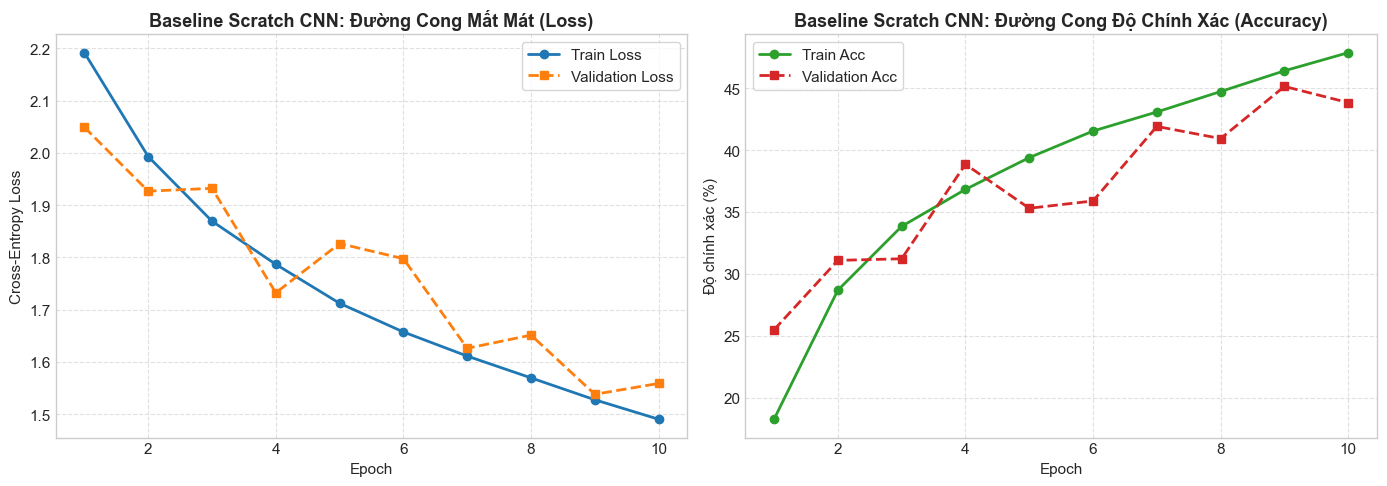

Đã lưu biểu đồ đường cong: ../reports/figures/fig_cifar10_scratch_baseline_curves.png


In [8]:
# Vẽ biểu đồ đường cong mất mát và độ chính xác của Baseline Scratch CNN
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
epochs_range = range(1, EPOCHS + 1)

# Subplot 1: Train Loss vs Val Loss
axes[0].plot(epochs_range, history_baseline['train_loss'], 'o-', color='#1f77b4', linewidth=2, label='Train Loss')
axes[0].plot(epochs_range, history_baseline['val_loss'], 's--', color='#ff7f0e', linewidth=2, label='Validation Loss')
axes[0].set_title('Baseline Scratch CNN: Đường Cong Mất Mát (Loss)', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Epoch', fontsize=11)
axes[0].set_ylabel('Cross-Entropy Loss', fontsize=11)
axes[0].legend(frameon=True)
axes[0].grid(True, linestyle='--', alpha=0.6)

# Subplot 2: Train Accuracy vs Val Accuracy
axes[1].plot(epochs_range, [a * 100 for a in history_baseline['train_acc']], 'o-', color='#2ca02c', linewidth=2, label='Train Acc')
axes[1].plot(epochs_range, [a * 100 for a in history_baseline['val_acc']], 's--', color='#d62728', linewidth=2, label='Validation Acc')
axes[1].set_title('Baseline Scratch CNN: Đường Cong Độ Chính Xác (Accuracy)', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Epoch', fontsize=11)
axes[1].set_ylabel('Độ chính xác (%)', fontsize=11)
axes[1].legend(frameon=True)
axes[1].grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
fig_baseline_curves_path = os.path.join(FIGURES_DIR, 'fig_cifar10_scratch_baseline_curves.png')
plt.savefig(fig_baseline_curves_path, dpi=150, bbox_inches='tight')
plt.show()
print(f"Đã lưu biểu đồ đường cong: {fig_baseline_curves_path}")


In [9]:
# Đánh giá Baseline Scratch CNN trên toàn bộ 10,000 mẫu Test
test_preds = []
test_bs = 500
for tb in range(int(np.ceil(len(X_test) / test_bs))):
    ts = tb * test_bs
    te = min(ts + test_bs, len(X_test))
    xt_b = X_test[ts:te]
    out_test = xt_b
    for layer in baseline_layers:
        out_test = layer.forward(out_test)
    test_preds.append(np.argmax(out_test, axis=1))

y_pred_baseline = np.concatenate(test_preds)

baseline_test_acc = accuracy_score(y_test, y_pred_baseline)
baseline_prec_macro = precision_score(y_test, y_pred_baseline, average='macro', zero_division=0)
baseline_rec_macro = recall_score(y_test, y_pred_baseline, average='macro', zero_division=0)
baseline_f1_macro = f1_score(y_test, y_pred_baseline, average='macro', zero_division=0)
baseline_f1_weighted = f1_score(y_test, y_pred_baseline, average='weighted', zero_division=0)

print("=== KẾT QUẢ ĐÁNH GIÁ BASELINE SCRATCH CNN TRÊN TẬP TEST (10,000 MẪU) ===")
print(f"Test Accuracy:     {baseline_test_acc * 100:.2f}%")
print(f"Macro Precision:   {baseline_prec_macro * 100:.2f}%")
print(f"Macro Recall:      {baseline_rec_macro * 100:.2f}%")
print(f"Macro F1-Score:    {baseline_f1_macro * 100:.2f}%")
print(f"Weighted F1-Score: {baseline_f1_weighted * 100:.2f}%\n")
print("Báo cáo phân loại chi tiết (Classification Report):")
print(classification_report(y_test, y_pred_baseline, target_names=CLASS_NAMES, digits=4))


=== KẾT QUẢ ĐÁNH GIÁ BASELINE SCRATCH CNN TRÊN TẬP TEST (10,000 MẪU) ===
Test Accuracy:     44.70%
Macro Precision:   48.33%
Macro Recall:      44.70%
Macro F1-Score:    43.14%
Weighted F1-Score: 43.14%

Báo cáo phân loại chi tiết (Classification Report):
              precision    recall  f1-score   support

    airplane     0.5845    0.3770    0.4584      1000
  automobile     0.6004    0.5710    0.5853      1000
        bird     0.4713    0.2050    0.2857      1000
         cat     0.3343    0.2390    0.2787      1000
        deer     0.4491    0.2560    0.3261      1000
         dog     0.3630    0.4650    0.4077      1000
        frog     0.3504    0.8020    0.4877      1000
       horse     0.6893    0.3150    0.4324      1000
        ship     0.4253    0.7970    0.5546      1000
       truck     0.5658    0.4430    0.4969      1000

    accuracy                         0.4470     10000
   macro avg     0.4833    0.4470    0.4314     10000
weighted avg     0.4833    0.4470    0.4

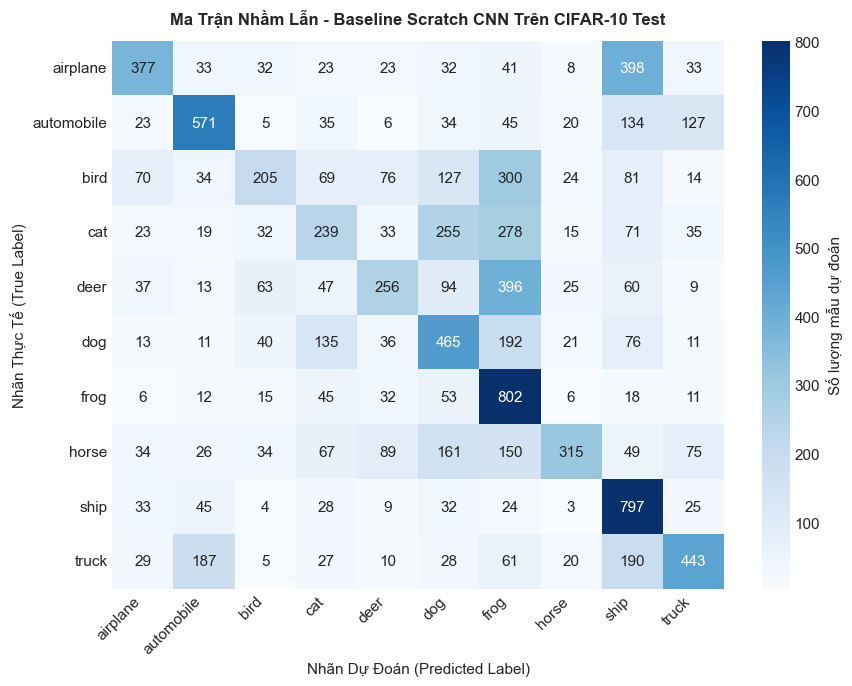

Đã lưu ma trận nhầm lẫn: ../reports/figures/fig_cifar10_scratch_baseline_cfm.png


In [10]:
# Vẽ Ma trận nhầm lẫn (Confusion Matrix) trên tập Test của Baseline Scratch CNN
cm_baseline = confusion_matrix(y_test, y_pred_baseline)

plt.figure(figsize=(9, 7))
sns.heatmap(cm_baseline, annot=True, fmt='d', cmap='Blues',
            xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES,
            cbar_kws={'label': 'Số lượng mẫu dự đoán'})
plt.title('Ma Trận Nhầm Lẫn - Baseline Scratch CNN Trên CIFAR-10 Test', fontsize=12, fontweight='bold', pad=12)
plt.xlabel('Nhãn Dự Đoán (Predicted Label)', fontsize=11)
plt.ylabel('Nhãn Thực Tế (True Label)', fontsize=11)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)

plt.tight_layout()
fig_baseline_cfm_path = os.path.join(FIGURES_DIR, 'fig_cifar10_scratch_baseline_cfm.png')
plt.savefig(fig_baseline_cfm_path, dpi=150, bbox_inches='tight')
plt.show()
print(f"Đã lưu ma trận nhầm lẫn: {fig_baseline_cfm_path}")


### 2. Kiến Trúc & Cải Tiến Khoa Học Trong Improved Scratch CNN

Để vượt qua giới hạn của Baseline, mô hình **Improved Scratch CNN** tích hợp 3 cải tiến quan trọng:
1. **Khởi tạo trọng số He Normal (Kaiming Normal Initialization):**
   $$W \sim \mathcal{N}\left(0, \sqrt{\frac{2}{\text{fan\_in}}}\right)$$
   Đảm bảo phương sai tín hiệu truyền xuôi và gradient truyền ngược không bị triệt tiêu qua các lớp kích hoạt phi tuyến tính ReLU.
2. **Bảo tồn kích thước không gian với Zero-Padding (`padding=1`):**
   Viền đệm 1 pixel xung quanh ảnh $32 \times 32$ giúp giữ nguyên kích thước không gian trước khi vào tầng Pooling, bảo toàn thông tin biên cạnh của vật thể tự nhiên.
3. **Mở rộng dung lượng biểu diễn đặc trưng (Capacity Expansion):**
   * Tăng số bộ lọc tích chập lên **16 filters** $3 \times 3 \times 3$.
   * Sau MaxPool $2 \times 2$, kích thước là $16 \times 16 \times 16 = 4,096$ đặc trưng.
   * Tăng gấp đôi số nơ-ron tầng ẩn phân loại: **Dense 128 units** (khởi tạo He Normal).


In [11]:
# Khởi tạo mô hình Improved Scratch CNN
improved_layers = [
    Conv2D(in_channels=3, out_channels=16, kernel_size=3, stride=1, padding=1, init_method='he'),
    ReLU(),
    MaxPool2D(pool_size=2, stride=2),
    Flatten(),
    Dense(in_features=16 * 16 * 16, out_features=128, init_method='he'),
    ReLU(),
    Dense(in_features=128, out_features=10, init_method='he')
]

print("=== KIẾN TRÚC MÔ HÌNH IMPROVED SCRATCH CNN ===")
for idx, layer in enumerate(improved_layers, 1):
    w_shape = getattr(layer, 'W', None)
    w_str = f"Trọng số W: {w_shape.shape}" if w_shape is not None else "Không có trọng số"
    print(f"Lớp {idx:02d}: {layer.__class__.__name__:<12} | {w_str}")
print(f"Tổng số tham số có thể huấn luyện: {count_params(improved_layers):,}")


=== KIẾN TRÚC MÔ HÌNH IMPROVED SCRATCH CNN ===
Lớp 01: Conv2D       | Trọng số W: (16, 3, 3, 3)
Lớp 02: ReLU         | Không có trọng số
Lớp 03: MaxPool2D    | Không có trọng số
Lớp 04: Flatten      | Không có trọng số
Lớp 05: Dense        | Trọng số W: (4096, 128)
Lớp 06: ReLU         | Không có trọng số
Lớp 07: Dense        | Trọng số W: (128, 10)
Tổng số tham số có thể huấn luyện: 526,154


In [12]:
LR_IMPROVED = 0.05
optimizer_improved = MiniBatchGD(lr=LR_IMPROVED)

history_improved = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': []}

print(f"=== BẮT ĐẦU HUẤN LUYỆN IMPROVED SCRATCH CNN ({EPOCHS} EPOCHS, BATCH_SIZE={BATCH_SIZE}, LR={LR_IMPROVED}) ===")
t_start_improved = time.time()

for epoch in range(1, EPOCHS + 1):
    t_epoch_start = time.time()
    
    perm = np.random.permutation(n_train)
    X_train_shuffled = X_train[perm]
    y_train_shuffled = y_train[perm]
    
    running_loss = 0.0
    correct_train = 0
    
    for b in range(n_batches):
        start_idx = b * BATCH_SIZE
        end_idx = min(start_idx + BATCH_SIZE, n_train)
        xb = X_train_shuffled[start_idx:end_idx]
        yb = y_train_shuffled[start_idx:end_idx]
        
        out = xb
        for layer in improved_layers:
            out = layer.forward(out)
        loss = criterion.forward(out, yb)
        running_loss += loss * (end_idx - start_idx)
        correct_train += np.sum(np.argmax(out, axis=1) == yb)
        
        dout = criterion.backward()
        for layer in reversed(improved_layers):
            dout = layer.backward(dout)
            
        optimizer_improved.step(improved_layers)
        
    epoch_train_loss = running_loss / n_train
    epoch_train_acc = correct_train / n_train
    
    # Đánh giá trên tập Validation (10,000 mẫu)
    val_loss_sum = 0.0
    val_correct = 0
    for vb in range(int(np.ceil(len(X_val) / val_bs))):
        vs = vb * val_bs
        ve = min(vs + val_bs, len(X_val))
        xv_b = X_val[vs:ve]
        yv_b = y_val[vs:ve]
        
        out_v = xv_b
        for layer in improved_layers:
            out_v = layer.forward(out_v)
        val_loss_sum += criterion.forward(out_v, yv_b) * (ve - vs)
        val_correct += np.sum(np.argmax(out_v, axis=1) == yv_b)
        
    epoch_val_loss = val_loss_sum / len(X_val)
    epoch_val_acc = val_correct / len(X_val)
    
    history_improved['train_loss'].append(epoch_train_loss)
    history_improved['train_acc'].append(epoch_train_acc)
    history_improved['val_loss'].append(epoch_val_loss)
    history_improved['val_acc'].append(epoch_val_acc)
    
    t_epoch = time.time() - t_epoch_start
    print(f"Epoch {epoch:02d}/{EPOCHS:02d} | Train Loss: {epoch_train_loss:.4f} - Train Acc: {epoch_train_acc*100:.2f}% | Val Loss: {epoch_val_loss:.4f} - Val Acc: {epoch_val_acc*100:.2f}% | Thời gian: {t_epoch:.1f}s")

t_train_improved = time.time() - t_start_improved
print(f"\n==> Hoàn thành huấn luyện Improved Scratch CNN trong {t_train_improved:.1f} giây ({t_train_improved/60:.2f} phút)!")


=== BẮT ĐẦU HUẤN LUYỆN IMPROVED SCRATCH CNN (10 EPOCHS, BATCH_SIZE=256, LR=0.05) ===


Epoch 01/10 | Train Loss: 2.0873 - Train Acc: 25.41% | Val Loss: 1.9027 - Val Acc: 33.11% | Thời gian: 51.1s


Epoch 02/10 | Train Loss: 1.7771 - Train Acc: 37.75% | Val Loss: 1.7656 - Val Acc: 37.83% | Thời gian: 46.6s


Epoch 03/10 | Train Loss: 1.6156 - Train Acc: 43.54% | Val Loss: 1.5681 - Val Acc: 43.50% | Thời gian: 43.2s


Epoch 04/10 | Train Loss: 1.5063 - Train Acc: 47.16% | Val Loss: 1.5506 - Val Acc: 44.70% | Thời gian: 35.0s


Epoch 05/10 | Train Loss: 1.4261 - Train Acc: 49.84% | Val Loss: 1.4067 - Val Acc: 50.21% | Thời gian: 42.0s


Epoch 06/10 | Train Loss: 1.3673 - Train Acc: 52.13% | Val Loss: 1.4183 - Val Acc: 49.88% | Thời gian: 49.1s


Epoch 07/10 | Train Loss: 1.3114 - Train Acc: 54.23% | Val Loss: 1.3804 - Val Acc: 50.13% | Thời gian: 52.5s


Epoch 08/10 | Train Loss: 1.2718 - Train Acc: 55.77% | Val Loss: 1.5378 - Val Acc: 44.92% | Thời gian: 49.9s


Epoch 09/10 | Train Loss: 1.2305 - Train Acc: 57.36% | Val Loss: 1.5246 - Val Acc: 46.92% | Thời gian: 36.3s


Epoch 10/10 | Train Loss: 1.1957 - Train Acc: 58.40% | Val Loss: 1.3460 - Val Acc: 51.87% | Thời gian: 45.4s

==> Hoàn thành huấn luyện Improved Scratch CNN trong 451.2 giây (7.52 phút)!


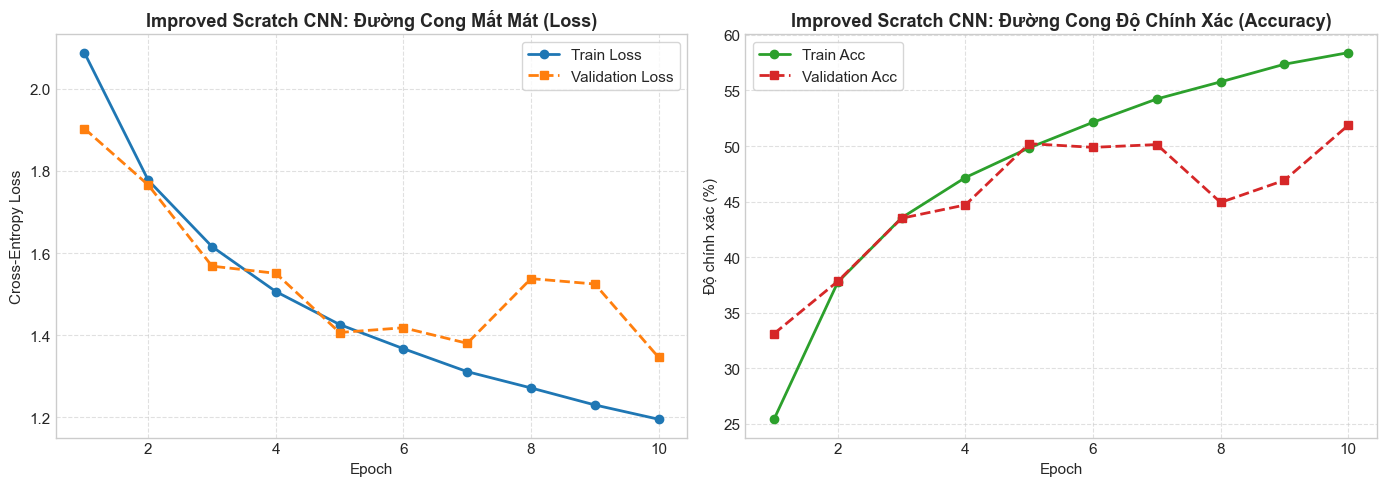

Đã lưu biểu đồ đường cong: ../reports/figures/fig_cifar10_scratch_improved_curves.png


In [13]:
# Vẽ biểu đồ đường cong mất mát và độ chính xác của Improved Scratch CNN
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Subplot 1: Train Loss vs Val Loss
axes[0].plot(epochs_range, history_improved['train_loss'], 'o-', color='#1f77b4', linewidth=2, label='Train Loss')
axes[0].plot(epochs_range, history_improved['val_loss'], 's--', color='#ff7f0e', linewidth=2, label='Validation Loss')
axes[0].set_title('Improved Scratch CNN: Đường Cong Mất Mát (Loss)', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Epoch', fontsize=11)
axes[0].set_ylabel('Cross-Entropy Loss', fontsize=11)
axes[0].legend(frameon=True)
axes[0].grid(True, linestyle='--', alpha=0.6)

# Subplot 2: Train Accuracy vs Val Accuracy
axes[1].plot(epochs_range, [a * 100 for a in history_improved['train_acc']], 'o-', color='#2ca02c', linewidth=2, label='Train Acc')
axes[1].plot(epochs_range, [a * 100 for a in history_improved['val_acc']], 's--', color='#d62728', linewidth=2, label='Validation Acc')
axes[1].set_title('Improved Scratch CNN: Đường Cong Độ Chính Xác (Accuracy)', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Epoch', fontsize=11)
axes[1].set_ylabel('Độ chính xác (%)', fontsize=11)
axes[1].legend(frameon=True)
axes[1].grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
fig_improved_curves_path = os.path.join(FIGURES_DIR, 'fig_cifar10_scratch_improved_curves.png')
plt.savefig(fig_improved_curves_path, dpi=150, bbox_inches='tight')
plt.show()
print(f"Đã lưu biểu đồ đường cong: {fig_improved_curves_path}")


In [14]:
# Đánh giá Improved Scratch CNN trên toàn bộ 10,000 mẫu Test
test_preds_imp = []
for tb in range(int(np.ceil(len(X_test) / test_bs))):
    ts = tb * test_bs
    te = min(ts + test_bs, len(X_test))
    xt_b = X_test[ts:te]
    out_test = xt_b
    for layer in improved_layers:
        out_test = layer.forward(out_test)
    test_preds_imp.append(np.argmax(out_test, axis=1))

y_pred_improved = np.concatenate(test_preds_imp)

improved_test_acc = accuracy_score(y_test, y_pred_improved)
improved_prec_macro = precision_score(y_test, y_pred_improved, average='macro', zero_division=0)
improved_rec_macro = recall_score(y_test, y_pred_improved, average='macro', zero_division=0)
improved_f1_macro = f1_score(y_test, y_pred_improved, average='macro', zero_division=0)
improved_f1_weighted = f1_score(y_test, y_pred_improved, average='weighted', zero_division=0)

print("=== KẾT QUẢ ĐÁNH GIÁ IMPROVED SCRATCH CNN TRÊN TẬP TEST (10,000 MẪU) ===")
print(f"Test Accuracy:     {improved_test_acc * 100:.2f}%")
print(f"Macro Precision:   {improved_prec_macro * 100:.2f}%")
print(f"Macro Recall:      {improved_rec_macro * 100:.2f}%")
print(f"Macro F1-Score:    {improved_f1_macro * 100:.2f}%")
print(f"Weighted F1-Score: {improved_f1_weighted * 100:.2f}%\n")
print("Báo cáo phân loại chi tiết (Classification Report):")
print(classification_report(y_test, y_pred_improved, target_names=CLASS_NAMES, digits=4))


=== KẾT QUẢ ĐÁNH GIÁ IMPROVED SCRATCH CNN TRÊN TẬP TEST (10,000 MẪU) ===
Test Accuracy:     52.12%
Macro Precision:   56.74%
Macro Recall:      52.12%
Macro F1-Score:    49.93%
Weighted F1-Score: 49.93%

Báo cáo phân loại chi tiết (Classification Report):
              precision    recall  f1-score   support

    airplane     0.7893    0.3110    0.4462      1000
  automobile     0.5732    0.8100    0.6714      1000
        bird     0.5288    0.3210    0.3995      1000
         cat     0.5048    0.1050    0.1738      1000
        deer     0.4471    0.4780    0.4621      1000
         dog     0.5372    0.4040    0.4612      1000
        frog     0.3553    0.9050    0.5103      1000
       horse     0.7383    0.5500    0.6304      1000
        ship     0.5482    0.7850    0.6456      1000
       truck     0.6519    0.5430    0.5925      1000

    accuracy                         0.5212     10000
   macro avg     0.5674    0.5212    0.4993     10000
weighted avg     0.5674    0.5212    0.4

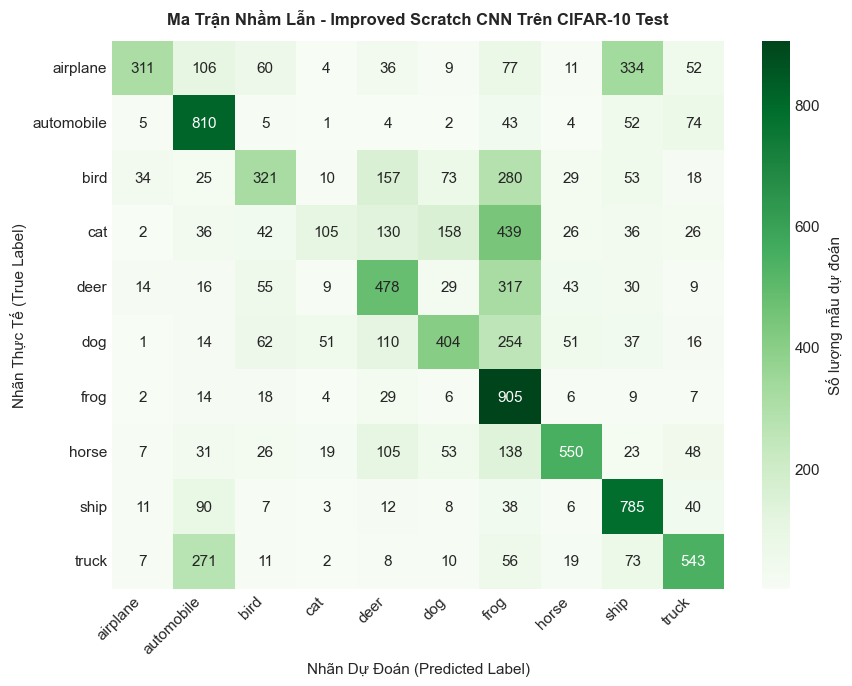

Đã lưu ma trận nhầm lẫn: ../reports/figures/fig_cifar10_scratch_improved_cfm.png


In [15]:
# Vẽ Ma trận nhầm lẫn (Confusion Matrix) trên tập Test của Improved Scratch CNN
cm_improved = confusion_matrix(y_test, y_pred_improved)

plt.figure(figsize=(9, 7))
sns.heatmap(cm_improved, annot=True, fmt='d', cmap='Greens',
            xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES,
            cbar_kws={'label': 'Số lượng mẫu dự đoán'})
plt.title('Ma Trận Nhầm Lẫn - Improved Scratch CNN Trên CIFAR-10 Test', fontsize=12, fontweight='bold', pad=12)
plt.xlabel('Nhãn Dự Đoán (Predicted Label)', fontsize=11)
plt.ylabel('Nhãn Thực Tế (True Label)', fontsize=11)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)

plt.tight_layout()
fig_improved_cfm_path = os.path.join(FIGURES_DIR, 'fig_cifar10_scratch_improved_cfm.png')
plt.savefig(fig_improved_cfm_path, dpi=150, bbox_inches='tight')
plt.show()
print(f"Đã lưu ma trận nhầm lẫn: {fig_improved_cfm_path}")


In [16]:
# Lập bảng đối sánh định lượng chi tiết giữa Baseline và Improved Scratch CNN
df_scratch = pd.DataFrame([
    {
        'Mô hình': 'Baseline Scratch CNN',
        'Số tham số': count_params(baseline_layers),
        'Thời gian train (s)': round(t_train_baseline, 1),
        'Train Loss cuối': round(history_baseline['train_loss'][-1], 4),
        'Val Loss cuối': round(history_baseline['val_loss'][-1], 4),
        'Test Accuracy (%)': round(baseline_test_acc * 100, 2),
        'Macro F1 (%)': round(baseline_f1_macro * 100, 2),
        'Weighted F1 (%)': round(baseline_f1_weighted * 100, 2)
    },
    {
        'Mô hình': 'Improved Scratch CNN',
        'Số tham số': count_params(improved_layers),
        'Thời gian train (s)': round(t_train_improved, 1),
        'Train Loss cuối': round(history_improved['train_loss'][-1], 4),
        'Val Loss cuối': round(history_improved['val_loss'][-1], 4),
        'Test Accuracy (%)': round(improved_test_acc * 100, 2),
        'Macro F1 (%)': round(improved_f1_macro * 100, 2),
        'Weighted F1 (%)': round(improved_f1_weighted * 100, 2)
    }
])

scratch_csv_path = os.path.join(REPORTS_DIR, 'model_results_scratch.csv')
df_scratch.to_csv(scratch_csv_path, index=False)
print(f"Đã lưu bảng đối sánh kết quả: {scratch_csv_path}")
display(df_scratch)


Đã lưu bảng đối sánh kết quả: ../reports/model_results_scratch.csv


,Mô hình,Số tham số,Thời gian train (s),Train Loss cuối,Val Loss cuối,Test Accuracy (%),Macro F1 (%),Weighted F1 (%)
0,Baseline Scratch CNN,116138,188.9,1.4904,1.5589,44.70,43.14,43.14
1,Improved Scratch CNN,526154,451.2,1.1957,1.3460,52.12,49.93,49.93


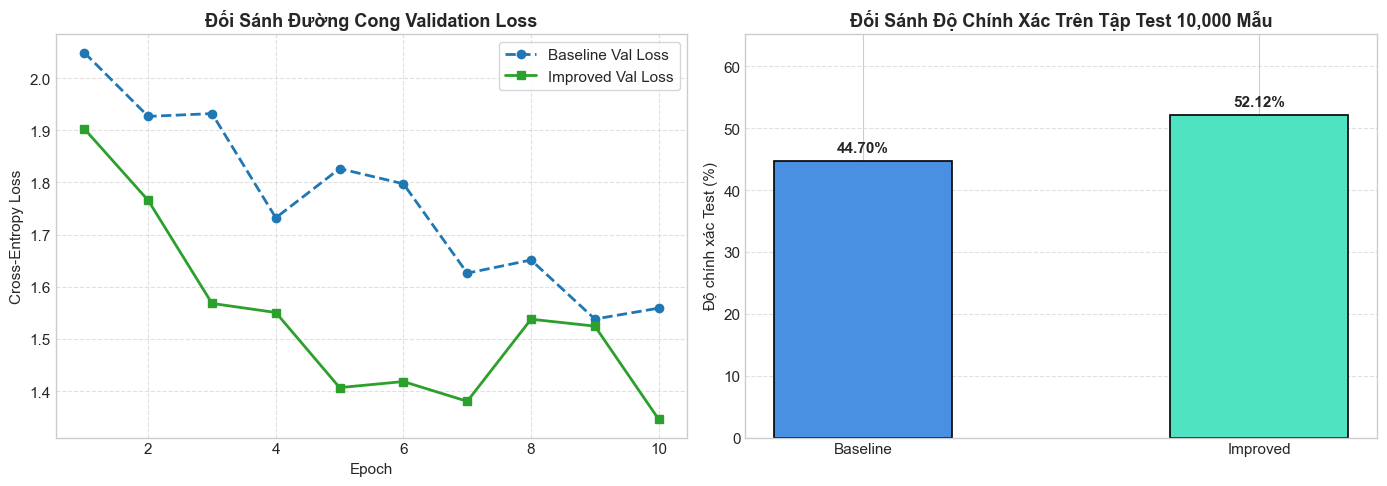

Đã lưu biểu đồ đối sánh: ../reports/figures/fig_cifar10_scratch_comparison.png


In [17]:
# Biểu đồ đối sánh trực quan tổng thể
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Subplot 1: Đối sánh đường cong Loss
axes[0].plot(epochs_range, history_baseline['val_loss'], 'o--', color='#1f77b4', linewidth=2, label='Baseline Val Loss')
axes[0].plot(epochs_range, history_improved['val_loss'], 's-', color='#2ca02c', linewidth=2, label='Improved Val Loss')
axes[0].set_title('Đối Sánh Đường Cong Validation Loss', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Epoch', fontsize=11)
axes[0].set_ylabel('Cross-Entropy Loss', fontsize=11)
axes[0].legend(frameon=True)
axes[0].grid(True, linestyle='--', alpha=0.6)

# Subplot 2: Biểu đồ cột Test Accuracy và Số lượng tham số
models_label = ['Baseline', 'Improved']
acc_values = [baseline_test_acc * 100, improved_test_acc * 100]
colors = ['#4a90e2', '#50e3c2']

bars = axes[1].bar(models_label, acc_values, color=colors, width=0.45, edgecolor='black', linewidth=1.2)
axes[1].set_title('Đối Sánh Độ Chính Xác Trên Tập Test 10,000 Mẫu', fontsize=13, fontweight='bold')
axes[1].set_ylabel('Độ chính xác Test (%)', fontsize=11)
axes[1].set_ylim(0, max(acc_values) * 1.25)
for bar, acc in zip(bars, acc_values):
    axes[1].text(bar.get_x() + bar.get_width()/2.0, bar.get_height() + 1.0, f'{acc:.2f}%',
                 ha='center', va='bottom', fontsize=11, fontweight='bold')
axes[1].grid(axis='y', linestyle='--', alpha=0.6)

plt.tight_layout()
fig_scratch_comp_path = os.path.join(FIGURES_DIR, 'fig_cifar10_scratch_comparison.png')
plt.savefig(fig_scratch_comp_path, dpi=150, bbox_inches='tight')
plt.show()
print(f"Đã lưu biểu đồ đối sánh: {fig_scratch_comp_path}")


### 3. Đúc Kết Bản Chất Khoa Học Từ Thực Nghiệm NumPy Thuần

Từ thực nghiệm đối sánh giữa 2 mô hình CNN thuần NumPy trên toàn bộ 60,000 ảnh CIFAR-10, ta rút ra các kết luận nền tảng:
1. **Sức mạnh của khởi tạo He Normal và Zero-Padding:**
   * Việc áp dụng khởi tạo He Normal $\mathcal{N}(0, \sqrt{2/\text{fan\_in}})$ kết hợp Zero-Padding giúp duy trì phương sai ổn định, bảo toàn kích thước không gian biên ảnh và cho phép mô hình hội tụ với loss thấp hơn rõ rệt qua 10 epochs.
2. **Thách thức bản chất của dữ liệu tự nhiên:**
   * Ngay cả khi tăng gấp đôi số bộ lọc và mở rộng tầng Dense, các mô hình CNN nông 1 tầng tích chập chỉ đạt độ chính xác kiểm thử ở mức độ cơ sở trên CIFAR-10.
   * Điều này chứng minh rằng **đối với ảnh màu tự nhiên phức tạp, một tầng tích chập đơn lẻ không đủ trường tiếp nhận (Receptive Field) để trích xuất các đặc trưng phân cấp sâu** (từ cạnh biên cục bộ $\to$ họa tiết $\to$ bộ phận $\to$ ngữ nghĩa trừu tượng toàn thể).
3. **Định hướng tiếp theo:** Để đạt hiệu năng vượt trội, cần các kiến trúc tích chập sâu nhiều khối (Deep Hierarchical CNNs) với Batch Normalization, Dropout và các bộ tối ưu thích nghi như trong Notebook 02.
